# Exerciții de bagging (împachtare)

![Bagging.png](Assets/Bagging.png)

# Obiectivele învățării

- Asocierea conceptelor de bootstrapping și agregare (cunoscute sub denumirea de „bagging”) pentru reducerea varianței
- Aplicarea algoritmului Random Forest care reduce și mai mult corelația observată în modelele de tip bagging


## Introducere

Pentru exercițiile din această săptămână, vom utiliza datele privind pierderea clienților din industria telecomunicațiilor pe care le-am folosit în săptămâna 1. Fișierul de date se numește `Orange_Telecom_Churn_Data.csv`. 

In [1]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix



## Întrebarea 1

* Importați datele privind evoluția clienților, care se găsesc în fișierul `Orange_Telecom_Churn_Data.csv`. 
* Eliminați toate coloanele care nu sunt susceptibile de a fi utilizate pentru predicție.
* Codificați tipurile de date după caz.

In [2]:
import pandas as pd
import numpy as np

# citim datele
filepath = os.sep.join(data_path + ['Orange_Telecom_Churn_Data.csv'])
data = pd.read_csv(filepath)

data.head(1).T

,0
state,KS
account_length,128
area_code,415
phone_number,382-4657
intl_plan,no
voice_mail_plan,yes
number_vmail_messages,25
total_day_minutes,265.1
total_day_calls,110
total_day_charge,45.07


Predicția cu siguranță nu ar trebui să includă numărul de telefon. Și este puțin probabil ca prefixul sau statul să fie dorit, cu excepția cazului în care există un motiv pentru a presupune că modelul are un factor geografic foarte specific.

In [3]:
# scoatem coloanele care nu ajuta la predictie
data = data.drop(['state', 'area_code', 'phone_number'], axis=1)

data.dtypes

account_length                     int64
intl_plan                            str
voice_mail_plan                      str
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churned                             bool
dtype: object

Examinați tipurile de date. Totul pare în regulă, cu excepția faptului că `int_plan` și `voice_mail_plan` trebuie să fie codificate boolean.

In [4]:
# yes/no -> 1/0
for col in ['intl_plan', 'voice_mail_plan']:
    data[col] = (data[col] == 'yes').astype(int)

data[['intl_plan', 'voice_mail_plan', 'churned']].head()

,intl_plan,voice_mail_plan,churned
0,0,1,False
1,0,1,False
2,0,0,False
3,1,0,False
4,1,0,False


## Întrebarea 2

* Examinați distribuția variabilei prezise (`churned`).
* Împărțiți datele în seturi de instruire și de testare. Decideți dacă ar trebui utilizată sau nu o împărțire stratificată pe baza distribuției.
* Examinați distribuția variabilei predictor în datele de instruire și de testare.

In [5]:
# distributia lui churned
data['churned'].value_counts(normalize=True)

churned
False    0.8586
True     0.1414
Name: proportion, dtype: float64

Având în vedere dezechilibrul variabilei predictoare, să împărțim datele, valorile *churned* fiind stratificate.

In [6]:
# impartim 70% train / 30% test, stratificat dupa churned
feature_cols = [c for c in data.columns if c != 'churned']

sss = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, test_idx = next(sss.split(data[feature_cols], data['churned']))

X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'churned']
X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'churned']

# distributia in train si test
pd.DataFrame({'train': y_train.value_counts(normalize=True),
              'test': y_test.value_counts(normalize=True)})

,train,test
churned,,
False,0.858571,0.858667
True,0.141429,0.141333


## Întrebare 3

* Potriviți modele de păduri aleatorii cu o serie de numere de arbori și evaluați eroarea din afara sacului pentru fiecare dintre aceste modele.
* Reprezentați grafic erorile oob rezultate ca funcție de numărul de arbori.

*Hint:* deoarece singurul lucru care se schimbă este numărul de arbori, se poate utiliza flagul `warm_start` astfel încât modelul să adauge de fiecare dată mai mulți arbori la modelul existent. Utilizați metoda `set_params` pentru a actualiza numărul de arbori.

In [7]:
# Suppress warnings about too few trees from the early models

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# warm_start=True -> la fiecare pas doar adauga arbori noi la model
RF = RandomForestClassifier(oob_score=True, warm_start=True, random_state=42, n_jobs=-1)

n_trees_list = [15, 20, 30, 40, 50, 100, 150, 200, 300, 400]
rf_oob = []

for n in n_trees_list:
    RF.set_params(n_estimators=n)
    RF.fit(X_train, y_train)
    rf_oob.append(1 - RF.oob_score_)   # eroarea oob

rf_oob_df = pd.DataFrame({'RandomForest': rf_oob}, index=n_trees_list)
rf_oob_df.index.name = 'n_trees'
rf_oob_df

,RandomForest
n_trees,
15,0.059714
20,0.053429
30,0.049714
40,0.047429
50,0.049143
100,0.045143
150,0.045143
200,0.044857
300,0.044286


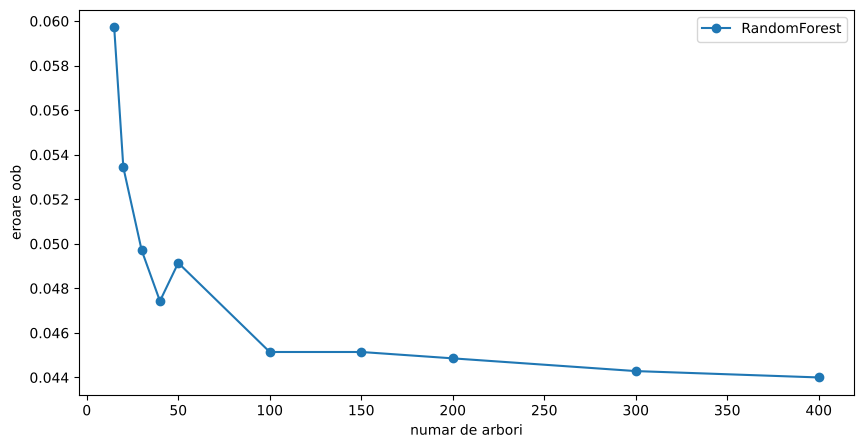

In [9]:
ax = rf_oob_df.plot(marker='o', figsize=(10, 5))
ax.set(xlabel='numar de arbori', ylabel='eroare oob');

## Întrebarea 4

* Repetați întrebarea 3 folosind arbori extra randomizați (`ExtraTreesClassifier`). Rețineți că parametrul `bootstrap` va trebui să fie setat la `True` pentru acest model.
* Comparați erorile de ieșire din sac pentru cele două tipuri diferite de modele.

In [10]:
# la fel, dar cu ExtraTrees (bootstrap=True ca sa avem eroare oob)
ET = ExtraTreesClassifier(oob_score=True, bootstrap=True, warm_start=True, random_state=42, n_jobs=-1)

et_oob = []

for n in n_trees_list:
    ET.set_params(n_estimators=n)
    ET.fit(X_train, y_train)
    et_oob.append(1 - ET.oob_score_)

et_oob_df = pd.DataFrame({'ExtraTrees': et_oob}, index=n_trees_list)
et_oob_df.index.name = 'n_trees'
et_oob_df

,ExtraTrees
n_trees,
15,0.080857
20,0.072000
30,0.069429
40,0.064286
50,0.067429
100,0.062857
150,0.061143
200,0.062571
300,0.060286


Combină cele două cadre de date într-unul singur pentru a ușura trasarea.

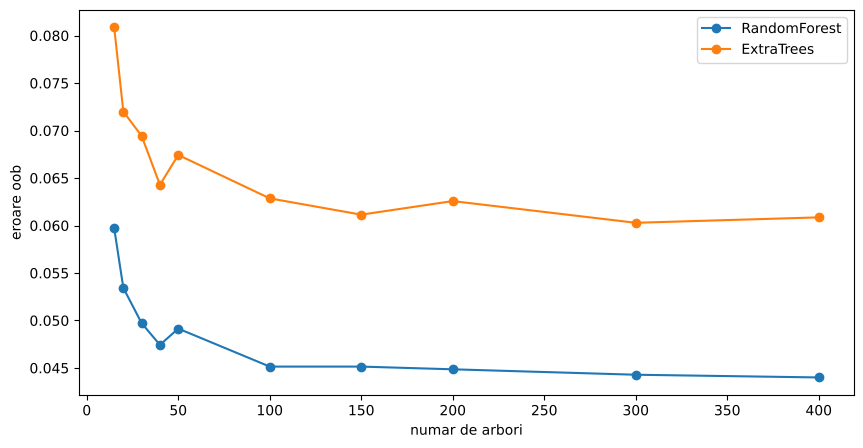

In [11]:
oob_df = pd.concat([rf_oob_df, et_oob_df], axis=1)

ax = oob_df.plot(marker='o', figsize=(10, 5))
ax.set(xlabel='numar de arbori', ylabel='eroare oob');

Modelul de pădure aleatorie are în mod constant rezultate mai bune decât arborii randomizați suplimentari.

## Întrebarea 5

* Selectați unul dintre modelele care se comportă bine și calculați parametrii de eroare și o matrice de confuzie pe setul de date de test. 
* Având în vedere distribuția clasei prezise, care metrică este cea mai importantă? Care ar putea fi înșelătoare?

In [12]:
# aleg random forest-ul cu 400 de arbori (e deja antrenat mai sus)
model = RF

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.96      0.99      0.98      1288
        True       0.95      0.77      0.85       212

    accuracy                           0.96      1500
   macro avg       0.96      0.88      0.91      1500
weighted avg       0.96      0.96      0.96      1500



In [13]:
pd.Series({'accuracy': accuracy_score(y_test, y_pred),
           'precision': precision_score(y_test, y_pred),
           'recall': recall_score(y_test, y_pred),
           'f1': f1_score(y_test, y_pred),
           'auc': roc_auc_score(y_test, y_prob)})

accuracy     0.961333
precision    0.947674
recall       0.768868
f1           0.848958
auc          0.923206
dtype: float64

Nu este surprinzător faptul că reamintirea este destul de slabă pentru clasa clienților care au renunțat (Adevărat), deoarece aceștia sunt destul de mici. Totuși, ne descurcăm mai bine decât ghicirile aleatorii, deoarece precizia este de 0,932 (față de 0,85 pentru ghicirile aleatorii).

**Raspuns:** Clasele sunt dezechilibrate (~86% `False`, ~14% `True`), deci cea mai importanta metrica e **recall** (si F1) pentru clasa `True`, pentru ca vrem sa prindem clientii care pleaca. **Accuracy** poate fi inselatoare: un model care zice mereu `False` ar avea si el ~86%.

## Întrebare 6

* Tipăriți sau vizualizați matricea de confuzie.
* Reprezentați grafic curbele ROC-AUC și precizie-rechemare.
* Reprezentarea grafică a importanței caracteristicilor.

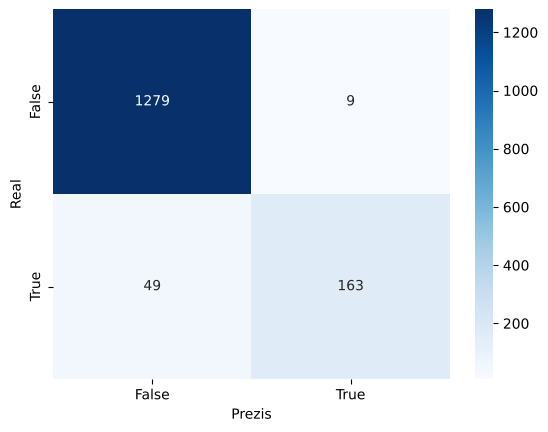

In [14]:
# matricea de confuzie
cm = confusion_matrix(y_test, y_pred)

ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                 xticklabels=['False', 'True'], yticklabels=['False', 'True'])
ax.set(xlabel='Prezis', ylabel='Real');

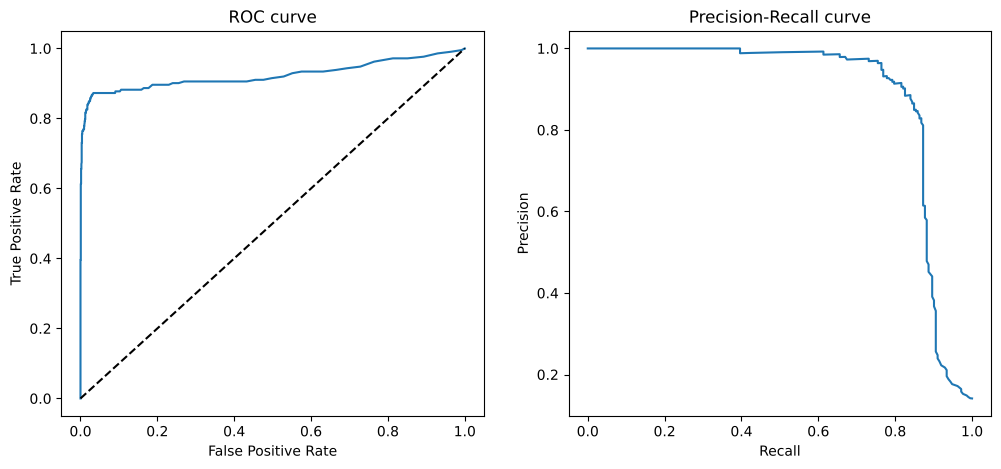

In [15]:
# curba ROC si curba precision-recall
fpr, tpr, _ = roc_curve(y_test, y_prob)
precision, recall, _ = precision_recall_curve(y_test, y_prob)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(fpr, tpr)
ax[0].plot([0, 1], [0, 1], 'k--')   # linia pentru ghicire aleatorie
ax[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC curve')

ax[1].plot(recall, precision)
ax[1].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall curve');

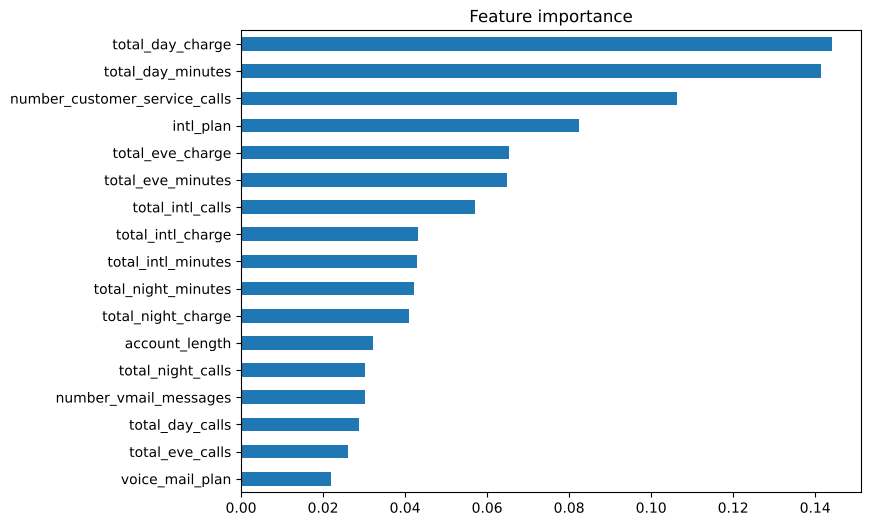

In [16]:
# importanta caracteristicilor
importance = pd.Series(model.feature_importances_, index=feature_cols).sort_values()

importance.plot(kind='barh', figsize=(8, 6), title='Feature importance');